# 03 · Method A: Multi-Signal Convergence Score

**Idea:** a real trend shows up in many *independent* places at once. Consumers
search for it, founders start companies, developers write code and
researchers publish, and the interest builds up over years. Hype tends to show
up in **attention only**, arrives suddenly, spikes, and is
**synchronised worldwide** because it is driven by media.

The score is built to be explainable to an investor. Each component is
one sentence, the weights are fixed in advance, and every number can be traced back to a
public data source.

| # | Component | Question it answers | Weight |
|---|---|---|---|
| 1 | **Breadth** | How many independent SF signal families (attention, founders, builders, research) are rising? | 0.30 |
| 2 | **Substance** | Are founders and builders growing at least as fast as the chatter? | 0.20 |
| 3 | **Persistence** | Has interest grown or held for several years, rather than one? | 0.15 |
| 4 | **Low spikiness** | Is the attention curve smooth rather than a spike? | 0.15 |
| 5 | **Holding** | Is interest still near its high, or already falling? | 0.10 |
| 6 | **Diffusion** | Does SEA *follow* SF (real diffusion) instead of spiking at the same moment (global hype)? | 0.10 |

**Pre-registration:** these weights were written down *before* running the backtest
(notebook 05). Notebook 05 also tests 2,000 random weightings to show the result
doesn't depend on this exact choice.

**No look-ahead:** `features_at(sector, t)` only sees yearly data up to year *t* and
monthly data up to December of *t*. Every feature is scale-free (ratios and growth rates),
so Google Trends' 0–100 rescaling, which uses the all-time maximum, cannot leak the future.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from radar.config import PROC, FIG, SECTORS, LABELLED, END_YEAR
warnings.filterwarnings("ignore")

monthly = pd.read_parquet(PROC / "panel_monthly.parquet")
yearly = pd.read_parquet(PROC / "panel_yearly.parquet")
sectors = pd.read_parquet(PROC / "sectors.parquet")
Y = {k: g.set_index("year")["value"].sort_index() for k, g in yearly.groupby(["sector", "signal"])}
M = {k: g.set_index("date")["value"].sort_index() for k, g in monthly.groupby(["sector", "signal"])}
EMPTY = pd.Series(dtype=float)
EMPTY_M = pd.Series(dtype=float, index=pd.DatetimeIndex([]))

WEIGHTS = dict(breadth=0.30, substance=0.20, persistence=0.15, low_spike=0.15, holding=0.10, diffusion=0.10)

## 1 · Building blocks (all point-in-time)

In [2]:
def y_upto(s, sig, t):
    x = Y.get((s, sig), EMPTY)
    return x[x.index <= t]

def m_upto(s, sig, t):
    x = M.get((s, sig), EMPTY_M)
    return x[x.index <= pd.Timestamp(f"{t}-12-31")]

def growth2(x, t):
    """2-year log growth of a 2-year average: (t-1,t) vs (t-3,t-2).
    eps is 5% of the running max, so the measure is scale-free and robust to zeros."""
    x = x.reindex(range(t - 3, t + 1))
    if x.isna().sum() > 1: return np.nan
    eps = 0.05 * x.max() if x.max() > 0 else np.nan
    if not eps or np.isnan(eps): return np.nan
    return float(np.log((x.loc[[t - 1, t]].mean() + eps) / (x.loc[[t - 3, t - 2]].mean() + eps)))

def sigmoid(z): return 1 / (1 + np.exp(-z))

FAMILIES = {"attention": ["gt_sf", "hn_share"], "founders": ["yc_share"],
            "builders": ["gh_share"], "research": ["oa_share"]}

def family_growth(s, t):
    out = {}
    for fam, sigs in FAMILIES.items():
        gs = [growth2(y_upto(s, sig, t), t) for sig in sigs]
        gs = [g for g in gs if not np.isnan(g)]
        out[fam] = np.mean(gs) if gs else np.nan
    return out

## 2 · The six components

In [3]:
def features_at(s, t):
    fg = family_growth(s, t)
    avail = {k: v for k, v in fg.items() if not np.isnan(v)}
    f = {f"g_{k}": v for k, v in fg.items()}

    # 1 Breadth: share of available families rising meaningfully (>10% over 2y)
    f["breadth"] = np.mean([v > 0.10 for v in avail.values()]) if len(avail) >= 2 else np.nan

    # 2 Substance: builders+founders growth minus attention growth
    sub = [fg[k] for k in ("founders", "builders") if not np.isnan(fg[k])]
    f["substance_raw"] = (np.mean(sub) - fg["attention"]) if sub and not np.isnan(fg["attention"]) else np.nan
    f["substance"] = sigmoid(f["substance_raw"]) if not np.isnan(f["substance_raw"]) else np.nan

    # 3-5 use monthly SF search interest
    m = m_upto(s, "gt_sf", t)
    m = m[m.index >= m[m > 0].index.min()] if (m > 0).any() else EMPTY
    if len(m) >= 24 and m.max() > 0:
        a = m.groupby(m.index.year).mean()
        a = a[a.index <= t].tail(5)
        yoy = a.diff().dropna().tail(4)
        runmax = a.cummax()
        # 3 Persistence: of the last 4 years, how many grew or held >=85% of running max
        f["persistence"] = float(((yoy > 0) | (a.loc[yoy.index] >= 0.85 * runmax.loc[yoy.index])).mean())
        # 4 Low spikiness: peak/median over the last 24 months -> 1/(1+log ratio)
        last24 = m.tail(24)
        ratio = last24.max() / max(last24.median(), 0.02 * m.max())
        f["spike_ratio"] = ratio
        f["low_spike"] = 1 / (1 + np.log(max(ratio, 1)))
        # 5 Holding: last-6-month level vs running max of the 6-month-smoothed series
        sm = m.rolling(6, min_periods=3).mean()
        f["holding"] = float(sm.iloc[-1] / sm.max())
        f["sf_active"] = float(a.iloc[-1] / runmax.iloc[-1])     # used to define evaluation window
    else:
        for k in ("persistence", "low_spike", "holding", "spike_ratio", "sf_active"): f[k] = np.nan

    # 6 Diffusion: contemporaneous correlation of 12-month changes, SF vs SEA, last 36 months.
    #   High same-month correlation = synchronised (global hype). Low = SEA not simply echoing.
    sea = m_upto(s, "gt_sea", t)
    if len(m) >= 48 and len(sea) >= 48:
        j = pd.concat([m, sea], axis=1, keys=["sf", "sea"]).dropna()
        d = np.log(j + 0.05 * j.max()).diff(12).dropna().tail(36)
        sync = d["sf"].corr(d["sea"]) if len(d) >= 24 and d.std().min() > 0 else np.nan
        f["sync"] = sync
        f["diffusion"] = 1 - max(sync, 0) if not np.isnan(sync) else np.nan
    else:
        f["sync"] = f["diffusion"] = np.nan

    # Momentum baseline = "follow the buzz": 2y growth of attention only
    f["baseline_momentum"] = fg["attention"]
    return f

def score_A(f, weights=WEIGHTS):
    num = sum(w * f[k] for k, w in weights.items() if not np.isnan(f.get(k, np.nan)))
    den = sum(w for k, w in weights.items() if not np.isnan(f.get(k, np.nan)))
    return num / den if den >= 0.5 else np.nan        # need at least half the evidence

## 3 · Compute for every sector and year (2009 to 2026)

In [4]:
rows = []
for s in SECTORS:
    for t in range(2009, END_YEAR + 1):
        f = features_at(s, t)
        f.update(sector=s, year=t, label=sectors.label[s], score_A=score_A(f))
        rows.append(f)
A = pd.DataFrame(rows)
A.to_parquet(PROC / "method_A_scores.parquet")
print(A.score_A.describe().round(3))
A.groupby("label")[list(WEIGHTS) + ["score_A"]].mean().round(2)

count    671.000
mean       0.607
std        0.179
min        0.046
25%        0.481
50%        0.610
75%        0.738
max        1.000
Name: score_A, dtype: float64


,breadth,substance,persistence,low_spike,holding,diffusion,score_A
label,,,,,,,
ambiguous,0.53,0.49,0.49,0.67,0.45,0.73,0.53
boom,0.61,0.51,0.87,0.75,0.84,0.81,0.70
candidate,0.60,0.52,0.63,0.68,0.64,0.74,0.60
noise,0.57,0.51,0.72,0.66,0.61,0.59,0.60


## 4 · Worked example: BNPL in 2018 vs NFTs in 2021
Both were "hot" in SF at the time. This compares what the evidence card said
for each, using only data available then.

In [5]:
def card(s, t):
    r = A[(A.sector == s) & (A.year == t)].iloc[0]
    return pd.Series({k: r[k] for k in list(WEIGHTS) + ["score_A", "spike_ratio", "sync", "g_attention", "g_founders", "g_builders", "g_research"]}, name=f"{s} {t}")

cards = pd.concat([card("bnpl", 2018), card("digital_banks", 2019), card("nft", 2021),
                   card("metaverse", 2022), card("daily_deals", 2011)], axis=1).round(2)
cards

,bnpl 2018,digital_banks 2019,nft 2021,metaverse 2022,daily_deals 2011
breadth,1.00,1.00,0.75,0.75,1.00
substance,NaN,0.63,0.11,0.10,0.52
persistence,1.00,1.00,NaN,NaN,1.00
low_spike,0.66,0.55,NaN,NaN,0.65
holding,1.00,1.00,NaN,NaN,0.97
diffusion,1.00,0.78,NaN,NaN,NaN
score_A,0.94,0.84,0.49,0.49,0.83
spike_ratio,1.67,2.29,NaN,NaN,1.71
sync,-0.67,0.22,NaN,NaN,NaN
g_attention,0.54,1.24,2.38,2.68,2.53


## 5 · Score trajectories for the labelled sectors

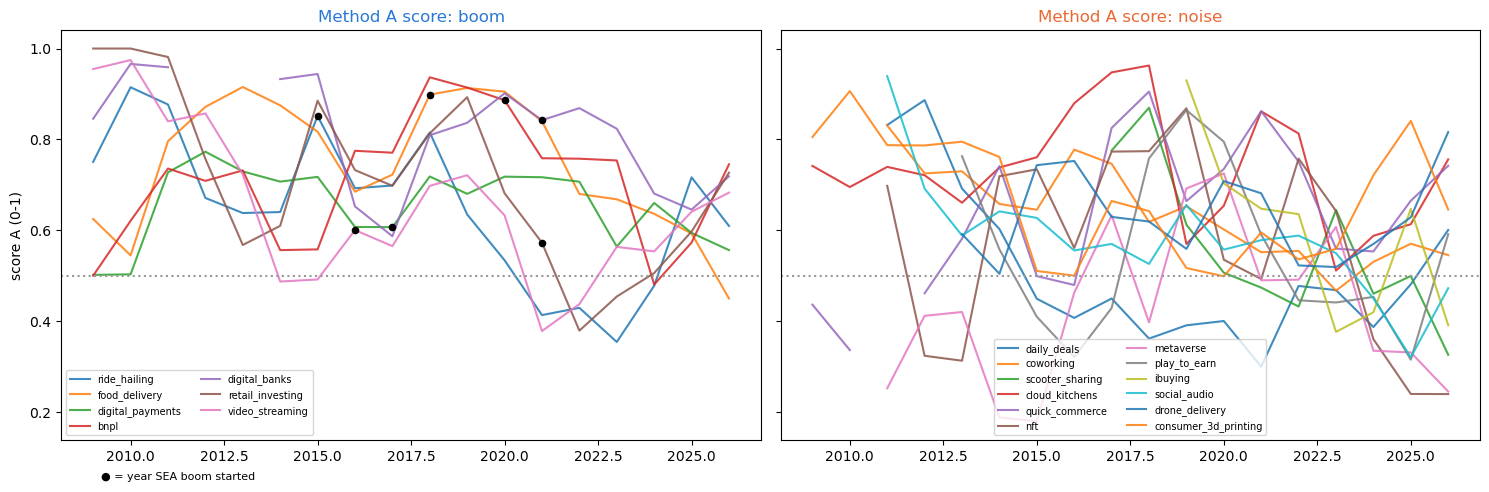

In [6]:
COL = {"boom": "#2a78d6", "noise": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, lbl in zip(axes, ["boom", "noise"]):
    for s in [x for x in LABELLED if sectors.label[x] == lbl]:
        d = A[A.sector == s].set_index("year")["score_A"]
        ax.plot(d.index, d.values, lw=1.5, alpha=.85, label=s)
        if pd.notna(sectors.sea_boom_year[s]):
            yb = int(sectors.sea_boom_year[s]); ax.scatter([yb], [d.get(yb, np.nan)], color="k", zorder=5, s=20)
    ax.axhline(0.5, color="#999", ls=":"); ax.set_title(f"Method A score: {lbl}", color=COL[lbl]); ax.legend(fontsize=7, ncol=2)
axes[0].set_ylabel("score A (0-1)"); axes[0].text(2009.2, 0.05, "● = year SEA boom started", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "03_scoreA_trajectories.png", dpi=150); plt.show()